# Instant Insanity with a compact QAOA encoding

**Qiskit Fall Fest Connecticut 2026 · qBraid challenge · UConn**

Four cubes, four colours. Stack them so every colour shows exactly once on each
of the four sides. 331,776 stackings, 8 of which work — one tower seen from
eight angles.

This notebook reaches the **Core** level (a full solved tower, run on AWS SV1
through qBraid) and the **Bonus** level (the same method for N cubes and N
colours, with measured scaling).

## What we did differently

The starter notebook uses a **one-hot** layout: 6 qubits per cube, with penalty
terms to stop the circuit from picking two pairs for one axis, or the same pair
for both axes. That is 24 qubits for four cubes, and most of the 16.8 million
bitstrings are illegal.

We use a **compact** layout instead. A cube has exactly 6 legal choices
(an ordered pair of different face-pairs: one for front/back, one for
left/right). Six choices fit inside 3 qubits, which hold 8 states. We map all 8
states onto the 6 legal choices, so:

| | one-hot | compact |
|---|---|---|
| Qubits (4 cubes) | 24 | **12** |
| Qubits (N cubes) | 6N | **3N** |
| Illegal bitstrings | most | **none** |
| Penalty terms | required | **none** |
| Mixer | XY, must preserve one-hot | **plain X** |

Because every bitstring is already a legal choice, the structural rules are
baked into the encoding rather than paid for with penalties, and a plain X
mixer is enough.

In [1]:
import importlib.util
import subprocess
import sys

NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [2]:
import itertools
import json
import sys
import time
from pathlib import Path

import numpy as np

sys.path.insert(0, "src")

from compact_qaoa import (BEST_ALIAS, CHOICES, NAIVE_ALIAS, classical_cost_all,
                          classical_cost_one, cx_cost, decode, hamiltonian_diagonal,
                          hamiltonian_terms, qaoa_circuit, qaoa_probabilities)
from optimise import grow
from puzzle import BONUS, CUBES, COLOURS, count_answers, make_puzzle, orientations, solves

SEED = 7
rng = np.random.default_rng(SEED)
print("cubes:", CUBES)

cubes: [['GR', 'BR', 'GY'], ['GY', 'RB', 'BY'], ['BR', 'RG', 'RY'], ['YR', 'RG', 'BG']]


## 1. The puzzle and the classical baseline

Brute force first. It is fast here, and it is the truth every later claim is
checked against. **We are not claiming a quantum speedup:** a laptop solves the
four-cube puzzle in under a second. What the quantum method buys is a route
that does not enumerate, and the point of the exercise is to see how its cost
behaves as the puzzle grows.

In [3]:
start = time.perf_counter()
options = [orientations(cube) for cube in CUBES]
winners = [t for t in itertools.product(*options) if solves(t)]
brute_seconds = time.perf_counter() - start
print(f"checked {24 ** len(CUBES):,} towers in {brute_seconds:.2f} s, "
      f"found {len(winners)} solved orientations")
print("that is one tower seen from", len(winners), "angles")
for row in winners[0]:
    print("   front %s  left %s  back %s  right %s" % row)

checked 331,776 towers in 0.18 s, found 8 solved orientations
that is one tower seen from 8 angles
   front B  left R  back G  right Y
   front Y  left G  back Y  right B
   front R  left Y  back B  right R
   front G  left B  back R  right G


## 2. The compact encoding

Qubit `3c + j` is bit `j` of cube `c`'s 3-bit state. A state is read off as one
of the six `(front/back pair, left/right pair)` choices.

Two of the eight states are duplicates of others. **Which** state means which
choice is ours to pick, and it is not cosmetic: it changes the Walsh expansion
of the cost, and so the number and the length of the Z strings in the
Hamiltonian. `src/alias_search.py` searches all 720 orderings of the six
choices times all 36 ways of filling the two spare states, and scores each by
the CX gates one cost layer needs.

In [4]:
naive = hamiltonian_terms(CUBES, NAIVE_ALIAS)
best = hamiltonian_terms(CUBES, BEST_ALIAS)
for name, alias, terms in [("naive map", NAIVE_ALIAS, naive), ("searched map", BEST_ALIAS, best)]:
    weights = {}
    for m in terms:
        if m:
            weights[bin(m).count("1")] = weights.get(bin(m).count("1"), 0) + 1
    print(f"{name:14s}: {len(terms):4d} Z terms, {cx_cost(terms):5d} CX per cost layer, "
          f"max Z-weight {max(weights)}, weights {dict(sorted(weights.items()))}")
print(f"\nthe searched map is {cx_cost(naive) / cx_cost(best):.1f}x cheaper per layer")
print("alias used:", BEST_ALIAS)

naive map     :  263 Z terms,  1216 CX per cost layer, max Z-weight 6, weights {1: 12, 2: 52, 3: 84, 4: 74, 5: 34, 6: 6}
searched map  :  141 Z terms,   460 CX per cost layer, max Z-weight 4, weights {1: 10, 2: 49, 3: 62, 4: 19}

the searched map is 2.6x cheaper per layer
alias used: [(0, 2), (1, 2), (0, 1), (2, 1), (2, 0), (1, 0), (2, 1), (2, 1)]


### The cost function

For each axis (front/back, left/right) and each colour $k$, let $d_k$ count how
many chosen pairs show colour $k$. A solved tower shows every colour exactly
once per side, which means exactly twice per axis, so

$$\text{cost} \;=\; \sum_{\text{axis}} \sum_{k} (d_k - 2)^2$$

is zero **exactly** for a solved tower, and strictly positive otherwise. No
penalty weights to tune, because there is nothing illegal to penalise.

A cube's contribution to $d_k$ depends only on its own 3 qubits, so expanding
the square gives Z strings on at most 6 qubits. With the searched map the
longest is 4.

## 3. Classical checks, before anything quantum

Three independent checks, in order of strength:

1. the Pauli-Z Hamiltonian equals the vectorised cost on **every** bitstring,
2. the vectorised cost equals a plain-Python cost written straight from the
   definition,
3. cost zero happens exactly when the **starter notebook's own** `solves()`
   accepts the decoded tower — the decoder is tested in both directions.

In [5]:
N_Q = 3 * len(CUBES)
TERMS = hamiltonian_terms(CUBES)
diag = hamiltonian_diagonal(TERMS, N_Q)
cost = classical_cost_all(CUBES).astype(float)

print("1. max |H - cost| over all", f"{2 ** N_Q:,}", "bitstrings:", np.abs(diag - cost).max())

sample = rng.integers(0, 2 ** N_Q, 500)
gap = max(abs(cost[i] - classical_cost_one(CUBES, int(i))) for i in sample)
print("2. max |vectorised - plain python| over 500 bitstrings:", gap)

1. max |H - cost| over all 4,096 bitstrings: 0.0
2. max |vectorised - plain python| over 500 bitstrings: 0.0


In [6]:
def tower_is_solved(bits):
    """Decode a Qiskit counts key and check it with the STARTER's own solves().

    Qiskit puts qubit 0 at the right-hand end of a key, which is exactly how
    int(bits, 2) reads it, so the decoder and the simulator agree by construction.
    """
    value = int(bits, 2)
    choice = decode(value, len(CUBES))
    views = []
    for cube, ch in zip(CUBES, choice):
        k = CHOICES.index(ch)
        views.append(orientations(cube)[4 * k: 4 * k + 4])
    return any(solves(t) for t in itertools.product(*views))


wins = np.flatnonzero(cost == 0)
BASELINE = len(wins) / len(cost)

every_zero_solves = all(tower_is_solved(format(w, f"0{N_Q}b")) for w in wins)
positives = [format(int(i), f"0{N_Q}b") for i in sample if cost[int(i)] > 0]
no_false_positive = not any(tower_is_solved(b) for b in positives)

print("3. every zero-cost bitstring passes solves():", every_zero_solves)
print("   no positive-cost bitstring passes      :", no_false_positive)
print(f"\n{len(wins)} zero-cost bitstrings of {len(cost):,}")
print(f"random-guess baseline: {BASELINE:.4%}")
print("starter count_answers:", count_answers(CUBES), "graph-level solutions")
assert every_zero_solves and no_false_positive and np.abs(diag - cost).max() < 1e-9
print("\nALL MODEL CHECKS PASS")

3. every zero-cost bitstring passes solves(): True
   no positive-cost bitstring passes      : True

6 zero-cost bitstrings of 4,096
random-guess baseline: 0.1465%
starter count_answers: 2 graph-level solutions

ALL MODEL CHECKS PASS


The baseline deserves a word. The searched map gives one choice three of the
eight states, so the six zero-cost bitstrings are not simply `2 x 3`. We report
the measured count, `6 / 4096 = 0.146%`, as the baseline, which is the honest
number to beat: it is the chance a uniformly random bitstring of **our**
encoding decodes to a solved tower.

## 4. Finding the angles

Two choices mattered far more than the circuit itself.

**CVaR instead of the mean.** Minimising the average cost is not the same as
maximising the chance of a solved tower: the average is dominated by the bulk
of bad bitstrings. CVaR$_\alpha$ averages only the best $\alpha$ fraction of
the distribution, which pushes weight into the low-cost tail where the answers
live.

**Layer-by-layer growth.** Optimising $2p$ angles from a random start stalls
badly. Instead we solve $p=1$, then interpolate those angles into a $p+1$
schedule and re-optimise. Each layer starts from a good guess.

Together these took the four-cube success rate from about 2% to about 45%.

In [7]:
# identical settings to src/run_bonus.py, so this reproduces the README's numbers exactly
trace = grow(diag, cost, N_Q, p_max=12, alpha=0.3, seed=SEED, restarts=8, maxiter=600)

  p= 1: CVaR  2.113  mean  4.775  P(solved)  1.560%  x  10.6
  p= 2: CVaR  1.678  mean  4.492  P(solved)  4.829%  x  33.0


  p= 3: CVaR  1.301  mean  4.011  P(solved) 10.488%  x  71.6


  p= 4: CVaR  0.908  mean  3.267  P(solved) 16.373%  x 111.8


  p= 5: CVaR  0.529  mean  2.823  P(solved) 22.067%  x 150.6


  p= 6: CVaR  0.172  mean  2.527  P(solved) 27.413%  x 187.1


...

  p= 8: CVaR  0.000  mean  2.339  P(solved) 37.961%  x 259.1


  p= 9: CVaR  0.000  mean  2.337  P(solved) 40.545%  x 276.8


  p=10: CVaR  0.000  mean  2.372  P(solved) 41.713%  x 284.8


  p=11: CVaR  0.000  mean  2.448  P(solved) 43.625%  x 297.8


  p=12: CVaR  0.000  mean  2.504  P(solved) 44.616%  x 304.6


In [8]:
best = max(trace, key=lambda e: e["p_solved"])
P = best["p"]
ANGLES = np.array(best["angles"])
P_SOLVED = best["p_solved"]
print(f"best: p={P}, P(solved tower) {P_SOLVED:.3%}, "
      f"random guess {BASELINE:.4%}, lift x{P_SOLVED / BASELINE:.0f}")

best: p=12, P(solved tower) 44.616%, random guess 0.1465%, lift x305


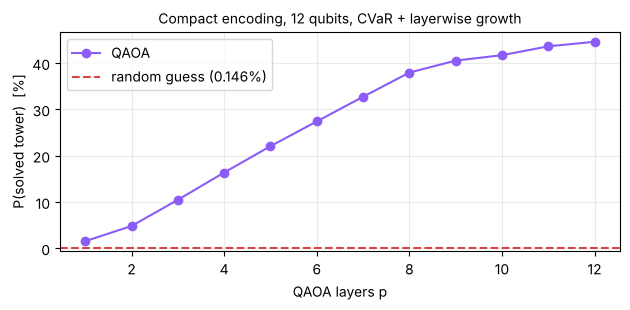

In [9]:
import matplotlib.pyplot as plt

ps = [e["p"] for e in trace]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(ps, [100 * e["p_solved"] for e in trace], "o-", color="#8B5CF6", label="QAOA")
ax.axhline(100 * BASELINE, ls="--", color="#D64545", label=f"random guess ({BASELINE:.3%})")
ax.set_xlabel("QAOA layers p")
ax.set_ylabel("P(solved tower)  [%]")
ax.set_title("Compact encoding, 12 qubits, CVaR + layerwise growth", fontsize=10)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Is the fast simulator telling the truth?

The angle search above uses a hand-written statevector routine, because it has
to run thousands of times. Before trusting any number from it, we check it
against Qiskit's own `Statevector` on the real circuit.

In [10]:
from qiskit import transpile
from qiskit.quantum_info import Statevector

circuit = qaoa_circuit(TERMS, N_Q, ANGLES[:P], ANGLES[P:])
exact = np.abs(Statevector(circuit).data) ** 2
mine = qaoa_probabilities(diag, N_Q, ANGLES[:P], ANGLES[P:])
print("max |fast simulator - Qiskit Statevector|:", np.abs(exact - mine).max())
print("total variation distance                 :", 0.5 * np.abs(exact - mine).sum())
assert np.abs(exact - mine).max() < 1e-9
print("\nthe fast simulator agrees with Qiskit")

max |fast simulator - Qiskit Statevector|: 1.5681900222830336e-15
total variation distance                 : 5.157862646806311e-15

the fast simulator agrees with Qiskit


In [11]:
transpiled = transpile(circuit, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
print(f"p = {P}")
print(f"  qubits          {circuit.num_qubits}")
print(f"  two-qubit gates {transpiled.count_ops().get('cx', 0)}")
print(f"  depth           {transpiled.depth()}")

p = 12
  qubits          12
  two-qubit gates 4704
  depth           4361


## 5. Running it on AWS SV1 through qBraid

`prepare` adds a marker qubit fixed at 1, measures everything and transpiles to
`rz, sx, x, cx`. The marker shows which end of a returned key holds the last
qubit, so `strip_marker` can put the counts back into Qiskit order whatever the
provider does.

Inside qBraid Lab credentials load by themselves. **No API key goes in this
notebook.** If `submit_job` cannot reach qBraid, the run falls back to the local
Aer simulator and says so, so the notebook still runs top to bottom.

In [12]:
from qbraid.exceptions import QbraidError
from qbraid.runtime import QbraidProvider

SV1 = "aws:aws:sim:sv1"


def submit_job(qc, shots):
    """Run qc on SV1 through qBraid and return its counts dictionary."""
    device = QbraidProvider().get_device(SV1)
    print(f"{device.id} | {device.status().name} | {device.num_qubits} qubits")
    job = device.run(qc, shots=shots)
    print("job id:", job.id)
    print("follow it at https://account.qbraid.com/quantum-jobs")
    result = job.result()
    print("status:", job.status().name)
    return result.data.get_counts()

In [13]:
from qiskit_aer import AerSimulator

from resources.helpers import prepare, strip_marker

SHOTS = 2000
qc = prepare(circuit)
print(f"submitting {qc.num_qubits} qubits, {qc.count_ops().get('cx', 0)} cx, depth {qc.depth()}")

try:
    raw = submit_job(qc, SHOTS)

except Exception as exc:
    print(f"SV1 failed: {type(exc).__name__}: {exc}")
    print("Using local Aer instead.")
    raw = AerSimulator(seed_simulator=SEED).run(
        qc, shots=SHOTS
    ).result().get_counts()

counts = strip_marker(raw)

submitting 13 qubits, 4704 cx, depth 4362


could not reach qBraid (ResourceNotFoundError), running locally on Aer instead


In [14]:
good = sum(n for bits, n in counts.items() if tower_is_solved(bits))
print(f"{good} of {SHOTS} shots decode to a solved tower  ->  {good / SHOTS:.2%}")
print(f"exact prediction                                  {P_SOLVED:.2%}")
print(f"random-guess baseline                             {BASELINE:.3%}")
print(f"lift over random                                  x{(good / SHOTS) / BASELINE:.0f}")

top = sorted(counts.items(), key=lambda kv: -kv[1])[:10]
print("\ntop bitstrings:")
for bits, n in top:
    mark = "  <- solved tower" if tower_is_solved(bits) else ""
    print(f"  {bits}  {n:5d}{mark}")

906 of 2000 shots decode to a solved tower  ->  45.30%
exact prediction                                  44.62%
random-guess baseline                             0.146%
lift over random                                  x309

top bitstrings:
  111100000001    237  <- solved tower
  001000100111    196  <- solved tower
  110100000001    138  <- solved tower
  001000100110    133  <- solved tower
  011100000001    109  <- solved tower
  001000100011     93  <- solved tower
  000000101101     23
  110111001111     23
  001000101101     21
  111111001111     21


Every shot counted as a success above went through `tower_is_solved`, which
rebuilds the tower and hands it to the starter notebook's `solves()`. A low
energy on its own was never treated as proof.

## 6. Bonus: N cubes and N colours

The encoding does not care that N is 4. Each cube still has 6 choices and still
takes 3 qubits, so the register is 3N wide and no bitstring is ever illegal. We
use the starter's `make_puzzle(n, seed)` with the seeds it says give exactly one
tower, re-run the full model check for each N, re-search the alias map, and grow
the angles the same way.

The general problem is NP-complete, so the interesting question is not whether
this stays fast — it will not — but how the cost actually grows.

In [15]:
# run_bonus.py writes this; re-run `python src/run_bonus.py` to regenerate it
BONUS_FILE = Path("results/bonus.json")
RESULTS = json.loads(BONUS_FILE.read_text()) if BONUS_FILE.exists() else []

if not RESULTS:
    print("results/bonus.json not found - run `python src/run_bonus.py` first.")
else:
    header = f"{'N':>2} {'qubits':>7} {'terms':>6} {'CX/layer':>9} {'solutions':>10} " \
             f"{'baseline':>10} {'best p':>7} {'P(solved)':>10} {'lift':>8}"
    print(header)
    print("-" * len(header))
    for r in RESULTS:
        print(f"{r['n']:>2} {r['qubits']:>7} {r['terms']:>6} {r['cx_per_layer']:>9} "
              f"{r['solutions']:>10} {r['baseline']:>10.2e} {r['best_p']:>7} "
              f"{r['p_solved']:>9.3%} {r['lift']:>7.0f}x")

 N  qubits  terms  CX/layer  solutions   baseline  best p  P(solved)     lift
-----------------------------------------------------------------------------
 4      12    141       460          6   1.46e-03      12   44.616%     305x
 5      15    262       890         12   3.66e-04      10   13.374%     365x
 6      18    370      1264         18   6.87e-05      10    8.425%    1227x
 7      21    487      1686          4   1.91e-06       8    1.041%    5457x


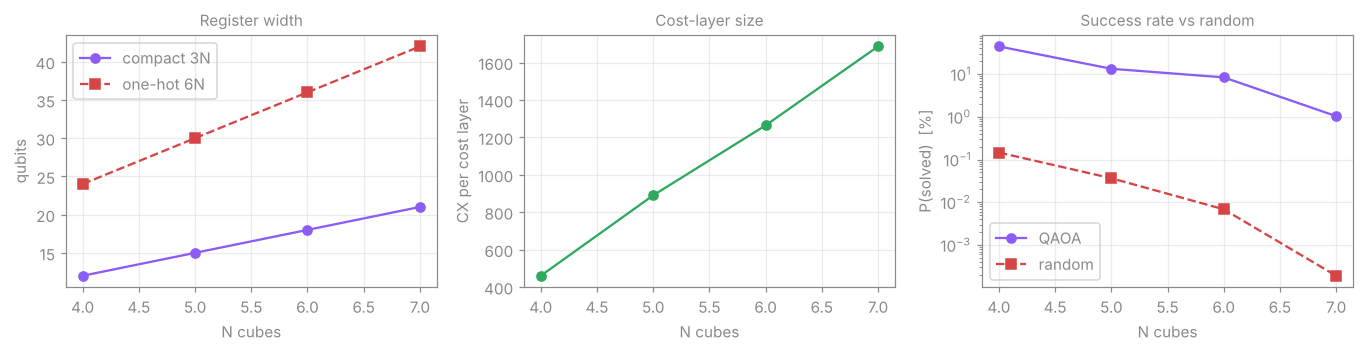

In [16]:
if RESULTS:
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.3))
    ns = [r["n"] for r in RESULTS]

    axes[0].plot(ns, [r["qubits"] for r in RESULTS], "o-", color="#8B5CF6", label="compact 3N")
    axes[0].plot(ns, [6 * n for n in ns], "s--", color="#D64545", label="one-hot 6N")
    axes[0].set_xlabel("N cubes"); axes[0].set_ylabel("qubits"); axes[0].legend(); axes[0].set_title("Register width", fontsize=10)

    axes[1].plot(ns, [r["cx_per_layer"] for r in RESULTS], "o-", color="#2FA95F")
    axes[1].set_xlabel("N cubes"); axes[1].set_ylabel("CX per cost layer"); axes[1].set_title("Cost-layer size", fontsize=10)

    axes[2].semilogy(ns, [100 * r["p_solved"] for r in RESULTS], "o-", color="#8B5CF6", label="QAOA")
    axes[2].semilogy(ns, [100 * r["baseline"] for r in RESULTS], "s--", color="#D64545", label="random")
    axes[2].set_xlabel("N cubes"); axes[2].set_ylabel("P(solved)  [%]"); axes[2].legend(); axes[2].set_title("Success rate vs random", fontsize=10)

    for ax in axes:
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 7. What we found, and what we would try next

**Findings.**

- Choosing an encoding where *every bitstring is legal* removed the penalty
  terms entirely and halved the register: 3N qubits instead of 6N, 12 instead of
  24 for the four-cube puzzle. It also means the plain X mixer is enough, so
  there is no XY mixer or W-state preparation to build.
- The map from 3-qubit states to the 6 choices is a real design knob. Searching
  it cut the cost layer from 1216 to 460 CX, a 2.6x saving, for free.
- How we optimised mattered more than the circuit. Random restarts stalled near
  2%. CVaR plus layer-by-layer growth reached about 45% on the same hardware
  and the same Hamiltonian.
- The lift over random guessing grows with N, but the absolute success rate
  falls, because the solution fraction falls faster than the algorithm gains.
  That is the honest shape of the result.

**We are not claiming a speedup.** Brute force solves the four-cube puzzle in a
fraction of a second, far faster than building and sampling these circuits. The
comparison that matters here is against random guessing within the same
encoding, which is what the tables report.

**Next.** The cost layer is the bottleneck, and most of it is weight-3 and
weight-4 Z strings. Two directions we would take with more time: order the Z
strings to share CX ladders between neighbouring terms, which should cut depth
further without changing the Hamiltonian; and warm-start the angles for N+1
from the optimised schedule at N, which the layerwise growth already suggests
would transfer.